# Поиск оптимальной стратегии N-шаговым методом SARSA

Реализуем поиск оптимальной стратегии по n-шаговому TD методу на основе SARSA. Опять же, пока что будем использовать "табличного" агента, код для которого у нас уже написан. Этот код копируем без изменений.

Напишем агента, обучающегося по методу n-шагового SARSA.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
import pickle

from abc import ABC, abstractmethod
from collections import defaultdict


class QTableAgent(ABC):
    def __init__(self, env, eps = 0.1, alpha = 0.1):
        self.nA = env.action_space.n # число действий
        self.N = defaultdict(lambda: np.zeros(self.nA))
        # заполняемая таблица значений Q-функции, хранящая ценности пар состояние-действие
        self.Q = defaultdict(lambda: np.zeros(self.nA))
    
        self.eps = eps   
        self.alpha = alpha

    # выбор eps-жадного действия        
    def reset(self):
        self.N = defaultdict(lambda: np.zeros(self.nA))
        self.Q = defaultdict(lambda: np.zeros(self.nA))

    # выбор eps-жадного действия        
    def get_action(self, state):
        if np.random.rand() < self.eps:
            return np.random.choice(self.nA)
        return self.best_action(state)
    
    # выбор жадного действия        
    def best_action(self, state):
        return np.argmax(self.Q[state])

    def get_Q(self, state, act):
        return self.Q[state][act]

    def update_Q(self, state, act, goal):
        # обновление оценки по методу выборочного среднего или с постоянным шагом обновления
        if self.alpha is None:
            self.N[state][act] += 1
            self.Q[state][act] += (goal - self.Q[state][act])/self.N[state][act]
        else:
            self.Q[state][act] += self.alpha*(goal - self.Q[state][act])

    @abstractmethod
    def learn(self):
        """Метод обучения"""
        pass

    def play(self, env, n_episodes):
        """Оценка качества обученного агента. """
        for _ in tqdm(range(n_episodes)):
            state, _ = env.reset()
            while True:
                # выбираем лучшие действия
                action = self.best_action(state)
                state, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    break

    def save_Q(self, name):
        os.makedirs('savedModels', exist_ok=True)
        with open('savedModels/TableAgent_'+name+".pkl",'wb') as f:
            pickle.dump(dict(self.Q), f)
        return 'savedModels/TableAgent_'+name+".pkl"
        
    def load_Q(self, name):
        self.reset()
        with open(name, 'rb') as f:
            loaded_data = pickle.load(f)
            self.Q = defaultdict(lambda: np.zeros(self.nA), loaded_data) 

In [2]:
from dataclasses import dataclass

@dataclass
class ConfigTD:
    gamma: float = 0.99
    eps_start: float = 1.0
    eps_decay: float = 0.999
    eps_min: float = 0.01
    alpha_start: float = 0.1
    alpha_decay: float = 0.99
    alpha_min: float = 0.05
    n: int = 10

class SARSA_Nstep_Agent(QTableAgent): 
    def __init__(self, env, config = None):
        super().__init__(env)
        if config is None:
            self.config = ConfigTD()
        else:
            self.config = config
            
        self.env = env
        self.alpha = self.config.alpha_start
        self.eps = self.config.eps_start
        self.gamma = self.config.gamma
        self.n = self.config.n

    def learn(self, n_episodes = 1000, restart = True):
        if restart == True:
            self.alpha = self.config.alpha_start
            self.eps = self.config.eps_start 
            self.reset()

        gammas =[self.gamma**i for i in range(self.n)]
        # ===== работа алгоритма обучения  =====
        for _ in tqdm(range(n_episodes)):
            state, _ = self.env.reset()
            action = self.get_action(state)
            # запускаем эпизод взаимодействия со средой

            states = []
            actions = []
            rewards = []
            while True:
                next_state, reward, terminated, truncated, _ = env.step(action)
                ### Store Experience ###
                states.append(state)
                actions.append(action)
                rewards.append(reward)
                
                next_action = self.get_action(next_state)

                
                if len(rewards) >= self.n:
                    upd_goal = sum([gammas[i] * rewards[i] for i in range(self.n)])
                    if not terminated:
                        upd_goal += self.gamma**self.n * self.get_Q(next_state, next_action)
                    self.update_Q(states[0], actions[0], upd_goal)

                    states.pop(0)
                    actions.pop(0)
                    rewards.pop(0)
                
                if terminated or truncated:
                    break
                state, action = next_state, next_action

            while rewards:
                upd_goal = sum([gammas[i] * rewards[i] for i in range(len(rewards))])
                self.update_Q(states[0], actions[0], upd_goal)
                states.pop(0)
                actions.pop(0)
                rewards.pop(0)

            # уменьшение доли шагов исследования
            self.eps = max(self.eps * self.config.eps_decay, self.config.eps_min)         
            if self.alpha is not None:
                self.alpha = max(self.alpha * self.config.alpha_decay, self.config.alpha_min)  

# Пример 1

Рассмотрим задачу об утёсе и продемонстрируем, что 10-шаговый метод SARSA быстрее достигает того же результата, что и SARSA.

In [3]:
import gymnasium as gym

# Создание среды
env = gym.make('CliffWalking-v1')
n_episodes = 250
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 1.0, 
                eps_decay = 0.9, 
                eps_min = 0.01,                
                alpha_start = 0.1, 
                alpha_decay = 1.0, 
                alpha_min = 0.01,
                n = 10
               )

# создание табличного агента
agent = SARSA_Nstep_Agent(env, config)


# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 250/250 [00:00<00:00, 877.38it/s]


Выведем график доходов за эпизоды, полученных в взаимодействия агента со средой.

In [4]:
import matplotlib.pyplot as plt
# для того, чтобы избежать ошибок при построении графиков
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

# в названии графика среднее вознаграждение за 20 последних эпизодов
def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(-100, 0)
    plt.show()

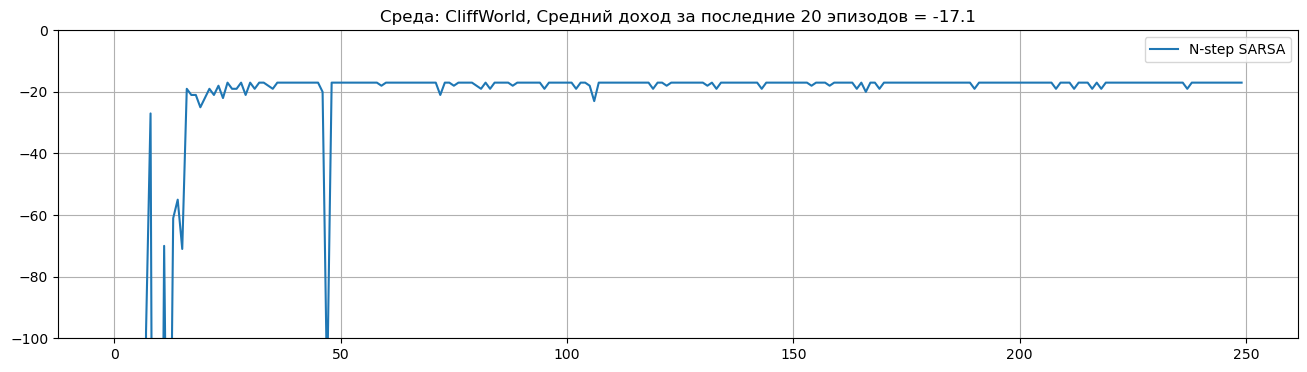

In [5]:
# график доходов
returns = np.array(env.return_queue)
plot_rewards("CliffWorld", returns, 'N-step SARSA')

Роль случайности конечно велика при обучении, но агент обучается той же стратегии, что и в обычном методе SARSA (безопасный путь длиной 17 шагов), в среднем примерно в 10 раз быстрее по сравнению с классическим SARSA.

In [26]:
import time
from IPython.display import clear_output

env = gym.make("CliffWalking-v1", render_mode='ansi')

state, _ = env.reset()
print(env.render())

while True:
    state, reward, terminated, truncated, _ = env.step(agent.best_action(state)) 
    
    time.sleep(.2)
    clear_output(wait=True)
    print(env.render())

    if terminated or truncated:
        break
    
env.close()

o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  x




# Пример 2


Рассмотрим также работу алгоритма n-шагового SARSA на примере задачи `MountainCar`. 

Напомним особенности: 
    
    1. Цель: въехать тележкой на вершину холма (позиция 0.5)
    2. Состояние: два числа, которые дают информацию о положении и скорости тележки по оси Ox, а именно
        
        [положение, скорость]
        
Положение в интервале [-1.2,0.6], скорость в интервале [-0.07,0.07]. Старт в случайном положении от -0.6 до -0.4 с нулевой скоростью. В данном случае агенту доступно лишь наблюдение о состоянии среды, так как полная информация включала бы x-, y-координаты тележки и вектор скорости. Тем не менее доступной информации достаточно, чтобы решить задачу обучения.

    3. Действия: [0,1,2], где 0 толкнуть влево, 1 не толкать, 2 толкнуть вправо.
    4. Вознаграждение: -1 за каждый временной шаг.
    5. Завершение: либо достижение вершины холма, либо достигнут максимум в 200 временных шагов.      

In [27]:
env = gym.make('MountainCar-v0')
state, _ = env.reset()
print("Начальное состояние: ", state)

Начальное состояние:  [-0.5232195  0.       ]


In [28]:
env = gym.make('MountainCar-v0', render_mode="human")
env.reset()
for _ in range(100):
    action = env.action_space.sample()
    state, reward, terminated, truncated, _ = env.step(action)
env.close()

D:\anaconda3\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


Для дискретизации потребуется класс-обёртка.

In [29]:
from gymnasium.wrappers import TransformObservation

# Вычислим шаг дискретизации
lower_bounds = env.observation_space.low
upper_bounds = env.observation_space.high
discrete_step = (upper_bounds - lower_bounds)/[20, 20]        
    
def modifyObs(obs):
    return tuple(np.int8((obs - lower_bounds)/discrete_step))

In [30]:
env = gym.make('MountainCar-v0')
env = TransformObservation(env, modifyObs, None)

# проверка работы: напечатаем первые 5 состояний
env.reset()
for _ in range(5):
    action = env.action_space.sample()
    state, reward, terminated, truncated, _ = env.step(action)
    print(state)

env.close()

(np.int8(8), np.int8(9))
(np.int8(8), np.int8(9))
(np.int8(8), np.int8(9))
(np.int8(8), np.int8(9))
(np.int8(8), np.int8(9))


In [40]:
# Создание среды c обёрткой
env = gym.make('MountainCar-v0', max_episode_steps = 5000)
env = TransformObservation(env, modifyObs, None)
n_episodes = 1000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 1.0, 
                eps_decay = 0.995, 
                eps_min = 0.001,                
                alpha_start = 0.2, 
                alpha_decay = 0.95, 
                alpha_min = 0.05,
                n=10
               )

# создание табличного агента
agent = SARSA_Nstep_Agent(env, config)

# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 1000/1000 [00:14<00:00, 67.10it/s]


In [10]:
# Создание среды c обёрткой
env = gym.make('MountainCar-v0', max_episode_steps = 5000)
env = TransformObservation(env, modifyObs, None)
n_episodes = 1000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

# создание табличного агента
agent = TableAgent(env)

# обучение агента и получение доходов по эпизодам
SARSA_Nstep_control(env, agent, n_episodes = n_episodes, gamma=0.99, 
                            eps_start=1.0, eps_decay = 0.995, eps_min = 0.001,
                       alpha_start=0.5, alpha_decay = 0.95,  alpha_min = 0.05, nstep=10)

100%|██████████| 1000/1000 [00:14<00:00, 66.85it/s]


Сначала обучению идёт очень медленно, так как при случайных действиях мала вероятность попасть на вершину холма. Первый успех возникает уже около 200 эпизода обучения. Затем обучение идёт гораздо быстрее.

In [32]:
print(agent.alpha)
print(agent.eps)

0.05
0.005988571720948768


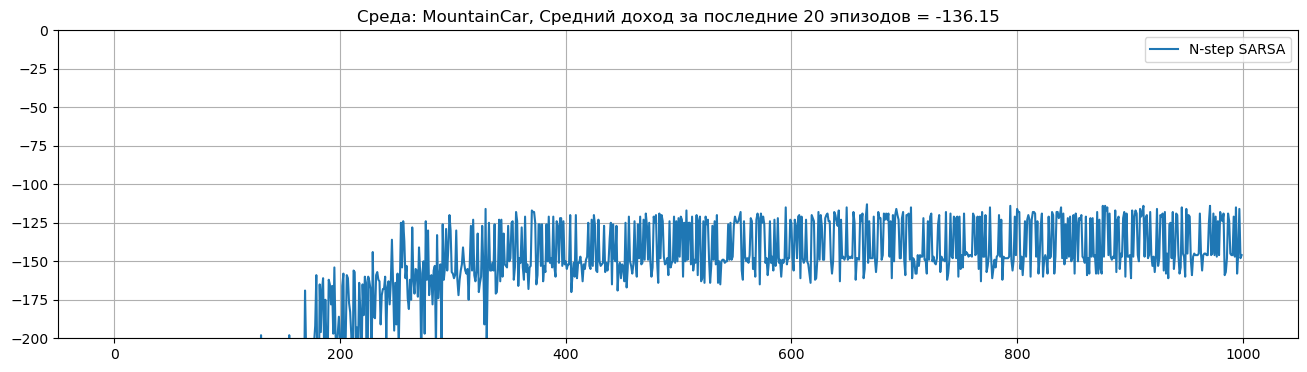

In [41]:
import matplotlib.pyplot as plt
# для того, чтобы избежать ошибок при построении графиков
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(-200, 0)
    plt.show()

# график доходов
returns = np.array(env.return_queue)
plot_rewards("MountainCar", returns, 'N-step SARSA')

In [42]:
agent.save_Q('MountCar_by_NstepSARSA_1K.pkl')

'savedModels/TableAgent_MountCar_by_NstepSARSA_1K.pkl.pkl'

Снова, по сравнению с 1-шаговыми методами, агенту потребовалось меньше эпизодов, чтобы достичь стратегии, гарантирующей достижение цели, хотя эта стратегия не оптимальна (лучший вариант - это среднее порядка 110 шагов).

In [43]:
# создание экземпляра среды
env = gym.make('MountainCar-v0')
env = TransformObservation(env, modifyObs, None)
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env, n_episodes)

print("Средний доход: ", np.mean(env.return_queue))
print("Минимальный доход: ", np.min(env.return_queue))

100%|██████████| 1000/1000 [00:03<00:00, 250.45it/s]

Средний доход:  -138.63
Минимальный доход:  -159.0


Ниже можно запустить демонстрацию работы агента.

In [44]:
# создание экземпляра среды
env = gym.make('MountainCar-v0', render_mode='human')
env = TransformObservation(env, modifyObs, None)
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env, 1)

print("Число шагов:", env.length_queue[-1])
# завершить взаимодействие со средой
env.close()

100%|██████████| 1/1 [00:04<00:00,  4.96s/it]

Число шагов: 145


In [17]:
modifyObs((1.0,0.05))

(np.int8(24), np.int8(17))

In [45]:
lower_bounds = env.observation_space.low
upper_bounds = env.observation_space.high
    
pos_grid = np.linspace(lower_bounds[0], upper_bounds[0], 20 * 2)  # более мелкая сетка для сглаживания
vel_grid = np.linspace(lower_bounds[1], upper_bounds[1], 20 * 2)
X, Y = np.meshgrid(pos_grid, vel_grid)
Z = np.zeros_like(X, dtype=int)

    # Для каждой точки определяем лучшее действие
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        obs = np.array([X[i, j], Y[i, j]])
        state = modifyObs(obs)
        Z[i, j] = agent.best_action(state)

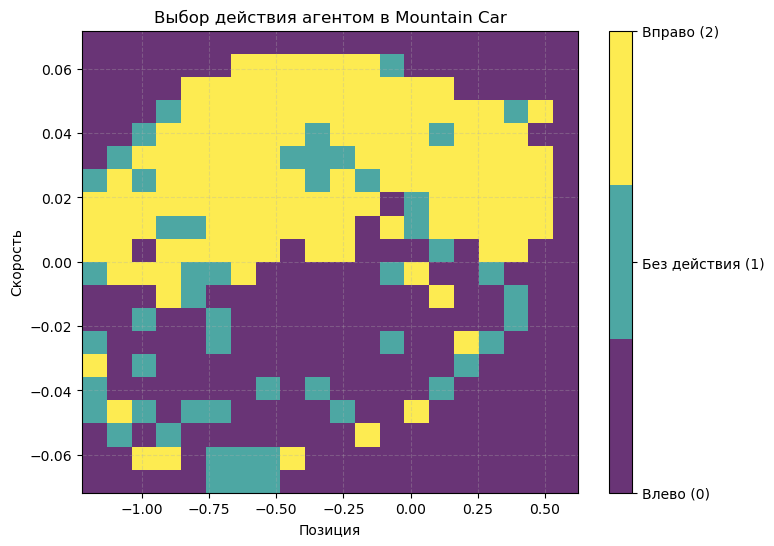

In [46]:
# Рисуем
plt.figure(figsize=(8, 6))
# Используем pcolormesh с дискретными цветами
cmap = plt.get_cmap('viridis', 3)  # три действия
mesh = plt.pcolormesh(X, Y, Z, cmap=cmap, shading='auto', alpha=0.8)
cbar = plt.colorbar(mesh, ticks=[0, 1, 2])
cbar.ax.set_yticklabels(['Влево (0)', 'Без действия (1)', 'Вправо (2)'])
plt.xlabel('Позиция')
plt.ylabel('Скорость')
plt.title('Выбор действия агентом в Mountain Car')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

### Задача

Обучить агента одним из изученных выше табличных методов, подобрав подходящую дискретизацию, в среде

    env = gym.make("Acrobot-v1")

Базовое описание среды можно найти по ссылке:

    https://gymnasium.farama.org/environments/classic_control/acrobot/

Цель в обучении агента, чтобы при прогоне на 1000 эпизодах средний доход превысил -105. 

Можно удвоить ценность задачи, если средний доход превысит -85.

In [47]:
import gymnasium as gym
# Создание среды
env = gym.make("Acrobot-v1")

In [48]:
from gymnasium.wrappers import TransformObservation
# Вычислим шаг дискретизации

def modifyObs(obs):
    ???

In [50]:
# Создание среды c обёрткой
env = gym.make("Acrobot-v1")
env = TransformObservation(env, modifyObs, None)

n_episodes = ???
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

# Настроить конфиг
config = ConfigTD( ??? )

# создание табличного агента
agent = SARSA_Nstep_Agent(env, config)

# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)


100%|██████████| 1000/1000 [00:10<00:00, 97.80it/s]


Проверка качества

In [57]:
# создание экземпляра среды
env = gym.make('Acrobot-v1')
env = TransformObservation(env, modifyObs, None)
n_episodes = 1000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

agent.play(env, n_episodes)

print("Средний доход: ", np.mean(env.return_queue))
print("Минимальный доход: ", np.min(env.return_queue))

100%|██████████| 1000/1000 [00:08<00:00, 118.90it/s]

Средний доход:  -84.342
Минимальный доход:  -174.0
